# 13. Modelo original: DES-CPL

Los capítulos 8 a 12 mostraron que los mejores modelos del benchmark empatan: XGBoost y Random Forest no se distinguen por Nemenyi, ni con un presupuesto de búsqueda cinco veces mayor (sección 12.2). Este capítulo propone un modelo que no compite con ellos sino que los combina: **DES-CPL**, una selección dinámica de ensambles que decide, para cada paciente, cuánto confiar en cada modelo según la calidad de sus probabilidades en pacientes parecidos.

El capítulo documenta el proceso completo, incluidos los intentos que no funcionaron, porque juntos responden una pregunta que va más allá del modelo: **¿dónde está el techo de desempeño de este problema y por qué?**

| Sección | Contenido |
|---|---|
| 13.1-13.2 | La limitación que motiva el modelo y su formulación, con la relación con la literatura |
| 13.3 | Piloto en un fold externo de la formulación inicial |
| 13.4 | Diagnóstico: ¿se puede saber qué modelo acierta con cada paciente? |
| 13.5 | Versión final (poda y encogimiento) en los cinco folds, con ablación |
| 13.6 | Búsqueda de alternativas: otros modelos de la lista y otra información |
| 13.7 | Síntesis: el límite explicativo de los datos |

**Qué es exploratorio y qué es definitivo.** Las secciones 13.3, 13.4 y 13.6 son exploratorias: sirvieron para diseñar el modelo y entender el problema, y se reportan completas, incluidos los resultados desfavorables. Las secciones 13.5 y 13.8 son las definitivas y siguen el protocolo registrado antes de ejecutarlas (`experiments/protocolo.md`); solo ellas sustentan la condición de superioridad.

**Cómo se ejecuta.** Los cálculos costosos están en scripts que escriben en `results/` y continúan donde quedaron si se interrumpen; el capítulo solo lee sus resultados. Para regenerarlos, en la raíz del repositorio:

```
python experiments/des_cpl.py --folds 0 1 2 3 4     # modelos base y DES-CPL (~45 min)
python experiments/diagnostico_errores.py            # sección 13.4 (minutos)
python experiments/cribado_modelos.py                # sección 13.6.1 (~20 min)
python experiments/cribado_modelos.py --folds 0 1 2 3 4 --candidatos "Extra Trees"
python experiments/limite_informativo.py             # sección 13.6.3 (~15 min)
```

El código del modelo está en `src/des_cpl.py` y el del protocolo en `src/experimento_des_cpl.py`, con sus pruebas en `tests/`.

In [1]:
from config import *

from scipy.stats import spearmanr
from sklearn.metrics import average_precision_score

from src import configuracion as cfg
from src import experimento_des_cpl as exd
from src.estadistica import correccion_holm, prueba_nadeau_bengio

cfg.N_JOBS = 4

# Versión definitiva: modelos base con la configuración elegida por Random
# Search con 60 evaluaciones (capítulo 12) y DES-CPL con 60 de Optuna.
CARPETA = RESULTADOS / "des_cpl_60"
RUTA_EVALUACION = RESULTADOS / "des_cpl_evaluacion_60.csv"
# Exploratorio: piloto de la formulación inicial con la configuración del E2.
RUTA_PILOTO = RESULTADOS / "des_cpl_evaluacion_v1.csv"
RUTA_DIAGNOSTICO = RESULTADOS / "des_cpl_diagnostico_errores.csv"
RUTA_CRIBADO = RESULTADOS / "cribado_modelos_fold0.csv"
RUTA_CRIBADO_FOLDS = RESULTADOS / "cribado_modelos_folds.csv"
RUTA_LIMITE = RESULTADOS / "limite_informativo.csv"
RUTA_SOTA = RESULTADOS / "benchmarks_sota.csv"     # LightGBM y CatBoost
FOLDS = [0, 1, 2, 3, 4]
BASE = list(exd.MODELOS)


def leer(ruta):
    if not ruta.exists():
        print(f"Falta {ruta.name}: ejecuta su script (ver la introducción).")
        return pd.DataFrame()
    return pd.read_csv(ruta)


mejores_e2 = exd.mejores_combinaciones(
    pd.read_csv(RESULTADOS / "tabla_maestra_clasificacion.csv"))
mejores = exd.con_presupuesto(mejores_e2, RESULTADOS / "convergencia_evaluaciones.csv",
                              RESULTADOS / "convergencia_reajustes.csv", exd.PRESUPUESTO)
pd.DataFrame({"balanceo": mejores["balanceo"],
              "AUC-PR con presupuesto E2": mejores_e2["auc_pr_media"],
              f"AUC-PR con {exd.PRESUPUESTO}": mejores["auc_pr_media"]}).round(4)

,balanceo,AUC-PR con presupuesto E2,AUC-PR con 60
modelo,,,
logistica,ninguno,0.2110,0.2109
bayes,ninguno,0.1995,0.1999
knn,ninguno,0.2058,0.2065
arbol,ninguno,0.2034,0.2021
random_forest,ninguno,0.2258,0.2237
xgboost,adasyn,0.2267,0.2290
svm,ninguno,0.2145,0.2145


## 13.1. La limitación: modelos que empatan en promedio pero no en cada paciente

Que dos modelos tengan el mismo AUC-PR medio no significa que acierten con los mismos pacientes. La tabla siguiente lo mide con las predicciones de prueba de los dos finalistas (capítulo 10): cuánto coinciden en el orden de riesgo, a cuántos pacientes señala uno y no el otro dentro del 15 % de mayor riesgo, y qué AUC-PR alcanzaría un *oráculo* que, para cada encuentro, eligiera el modelo que más se acerca a su etiqueta. El oráculo no es alcanzable, porque usa la etiqueta; es la cota superior de lo que podría ganar una combinación que eligiera bien el modelo de cada paciente.

In [2]:
prueba = pd.read_csv(RESULTADOS / "predicciones_prueba.csv")
y_prueba = prueba.pop("y_real").to_numpy()
a, b = prueba["p_xgboost (adasyn)"].to_numpy(), prueba["p_random_forest (ninguno)"].to_numpy()

corte_a, corte_b = np.quantile(a, 0.85), np.quantile(b, 0.85)
solo_uno = ((a >= corte_a) != (b >= corte_b)).mean()
oraculo = np.where(np.abs(a - y_prueba) < np.abs(b - y_prueba), a, b)

complementariedad = pd.DataFrame({
    "indicador": ["Correlación de Spearman entre los dos modelos",
                  "Encuentros señalados por uno solo (15 % de mayor riesgo)",
                  "AUC-PR de XGBoost", "AUC-PR de Random Forest",
                  "AUC-PR del promedio de los dos",
                  "AUC-PR del oráculo (cota superior)"],
    "valor": [spearmanr(a, b).statistic, solo_uno,
              average_precision_score(y_prueba, a),
              average_precision_score(y_prueba, b),
              average_precision_score(y_prueba, (a + b) / 2),
              average_precision_score(y_prueba, oraculo)],
}).round(4)
guardar_resultado(complementariedad, "des_cpl_complementariedad")
complementariedad

,indicador,valor
0,Correlación de Spearman entre los dos modelos,0.9055
1,Encuentros señalados por uno solo (15 % de may...,0.0631
2,AUC-PR de XGBoost,0.2285
3,AUC-PR de Random Forest,0.2279
4,AUC-PR del promedio de los dos,0.2324
5,AUC-PR del oráculo (cota superior),0.3277


Los dos modelos ordenan casi igual a los pacientes, pero no señalan exactamente a los mismos, y la distancia entre su AUC-PR y la del oráculo es grande. Promediar ya recupera una parte. La pregunta del modelo original es si una combinación que **dependa del paciente** recupera más que el promedio, que aplica la misma regla a todos.

## 13.2. Formulación

DES-CPL tiene cuatro componentes. La formulación completa, con sus dos proposiciones, está en el artículo; aquí se resume.

1. **Conjunto de selección fuera de pliegue.** Cada modelo base $f_m$ se reentrena en una validación cruzada de tres pliegues agrupada por paciente, y para cada encuentro se guarda la probabilidad del modelo que no lo vio, $\tilde f_m(x_i)$. Medir la competencia sobre los encuentros de entrenamiento haría parecer competentes a todos los modelos.
2. **Región de competencia estratificada y agrupada.** La posición de un encuentro es su perfil de salida, $\phi(x) = (\operatorname{logit} f_1(x), \dots, \operatorname{logit} f_M(x))$. La región reúne sus $k$ vecinos positivos y sus $k$ vecinos negativos más cercanos en ese espacio, excluyendo los encuentros del mismo paciente. Con un 11 % de positivos, una región sin estratificar casi nunca tendría positivos.
3. **Competencia por Brier local.** La competencia de cada modelo es su puntuación de Brier en la región, que mide la calidad de la probabilidad y no solo el acierto de la etiqueta:
$$
C_m(x) = \hat q(x)\,\frac{1}{k}\sum_{i \in \mathcal N_k^+(x)} \big(\tilde f_m(x_i) - 1\big)^2 + \big(1 - \hat q(x)\big)\,\frac{1}{k}\sum_{i \in \mathcal N_k^-(x)} \tilde f_m(x_i)^2 ,
$$
donde $\hat q(x)$ es la prevalencia local: la proporción de positivos entre los $2k$ vecinos de $x$ sin estratificar, suavizada hacia la prevalencia global.
4. **Ponderación softmax con temperatura.** $w_m(x) \propto \exp(-C_m(x)/\tau)$ y $\hat f(x) = \sum_m w_m(x) f_m(x)$. Con $\tau \to \infty$ es el promedio simple; con $\tau = 0$, la selección del modelo localmente mejor.

**Una corrección al diseño inicial.** La primera versión ponderaba cada clase con $1/2$ (Brier balanceado). Esa medida no es una regla de puntuación propia para el riesgo de la zona: en una región con la mitad de positivos, la probabilidad que minimiza el Brier balanceado es $0.5$ aunque el riesgo real de la zona sea del 5 %, de modo que premia al modelo cuya probabilidad está más cerca de $0.5$, que en este problema es casi siempre el de probabilidad más alta. Con la prevalencia local, la región sigue garantizando positivos (lo que reduce la varianza de la estimación en la clase minoritaria) y la reponderación devuelve a cada clase su peso real: es el estimador estratificado del Brier de la zona. El piloto (13.3) compara las dos versiones.


### 13.2.1. Relación con la literatura y qué es nuevo

La selección dinámica de ensambles no aparece en los artículos de readmisión en pacientes diabéticos de las búsquedas en Web of Science y Scopus (257 y 83 registros), ni en una búsqueda complementaria. El trabajo más cercano en readmisión es el de Shi et al. (2025), que aplica META-DES con regiones de competencia definidas por complicaciones a pacientes con cirrosis, y que reporta que los métodos de selección dinámica existentes no siempre superan a los ensambles del estado del arte en datos tabulares. Nótese que el conjunto «diabetes» que aparece en los bancos de prueba de selección dinámica (Pima) es de diagnóstico de diabetes, no de readmisión.

Cada componente de DES-CPL tiene antecedentes, y la novedad está en cómo se combinan y en el problema:

| Componente | Antecedente | Diferencia en DES-CPL |
|---|---|---|
| Región en el espacio de salidas | KNOP (Cavalcanti et al.) | Logit de las probabilidades, no votos |
| Competencia probabilística | RRC (Woloszynski y Kurzynski, 2011) | Mide la calidad de la probabilidad (Brier), no la probabilidad de acertar la etiqueta |
| Competencia por error | Selección dinámica de regresores (Rooney et al.) | Aplicada a probabilidades de clasificación con clases desbalanceadas |
| Región con ambas clases | KNORA-B/BI, DES-MI (García et al., 2018) | Además repondera cada clase con la prevalencia local estimada: estimador estratificado del Brier de la zona |
| Exclusión del paciente | — | Necesaria cuando un paciente tiene varios encuentros |
| Encogimiento local-global (13.5) | — | Mezcla la competencia local con la global con λ elegido en los datos; no lo encontramos en la literatura de selección dinámica |
| Poda (13.5) | Selección estática de clasificadores | Se decide en el conjunto de selección, antes de la combinación dinámica |

## 13.3. Piloto: la formulación inicial en un fold externo

**Objetivo.** Antes de los cinco folds, el piloto respondió tres preguntas con un costo de cómputo cinco veces menor: (1) si el protocolo reproduce los modelos base del Entregable 2, (2) cuál de las dos ponderaciones se adopta y (3) si la formulación inicial supera a los modelos base. Esta sección conserva sus resultados tal como se obtuvieron, antes de los cambios de la sección 13.5.

**Diseño.** Se usa el fold externo 0 del Entregable 2. Cada modelo base conserva su mejor combinación de balanceo y los hiperparámetros que eligió su bucle interno **en ese fold**, de modo que DES-CPL no recibe información que los modelos base no tuvieron. Se comparan:

| Familia | Métodos |
|---|---|
| Modelos base | Los siete, ajustados con todo el entrenamiento del fold |
| Ensambles estáticos | Promedio simple; apilamiento con regresión logística sobre los perfiles; pesos globales (la misma softmax con el Brier de cada modelo en todo el conjunto de selección, que aísla lo que aporta que la competencia sea local) |
| Modelo original | DES-CPL con ponderación por prevalencia local y con Brier balanceado |
| Ablación | Competencia por exactitud, región sin estratificar, sin excluir al paciente, selección dura ($\tau = 0$) |

Los hiperparámetros de cada método ($k \in \{5, 10, 20, 30, 50, 100\}$ y diez valores de $\tau$ entre $0$ e $\infty$: 60 configuraciones, el presupuesto validado en el capítulo 12) se eligen maximizando el AUC-PR **en el conjunto de selección**, sin tocar el fold de evaluación.

**Regla de decisión, fijada antes de ver el fold de evaluación.** La ponderación que se adopta es la de mayor AUC-PR en el conjunto de selección; el fold de evaluación solo se usa para reportar. Un fold no basta para afirmar superioridad: las pruebas de hipótesis se hacen con los cinco.

In [3]:
# Las predicciones de los modelos base se calculan una vez por fold y se
# reutilizan en todo el capítulo (experiments/des_cpl.py hace lo mismo).
estado = exd.progreso(CARPETA, FOLDS)
if (estado["estado"] != "Completo").any():
    train = leer_tabla("diabetes_train")
    roles = roles_variables()
    PREDICTORES = (roles["numericas"] + roles["ordinales"]
                   + roles["binarias"] + roles["categoricas"])
    X, y = train[PREDICTORES], train[roles["objetivo"]]
    grupos = train[roles["identificador"]]
    particiones = exd.particiones_externas(X, y, grupos)
    for fold in estado.query("estado != 'Completo'")["fold"]:
        exd.ejecutar_fold(fold, particiones[fold], X, y, grupos, roles, mejores,
                          CARPETA, razon_desbalance=float((1 - y.mean()) / y.mean()))
    estado = exd.progreso(CARPETA, FOLDS)
estado

,fold,modelos listos,faltan,estado
0,0,7,—,Completo
1,1,7,—,Completo
2,2,7,—,Completo
3,3,7,—,Completo
4,4,7,—,Completo


### 13.3.1. Control: reproducción de los modelos base

El modelo final de cada base es el mismo pipeline, con los mismos hiperparámetros y la misma semilla, ajustado con los mismos datos que en el estudio de convergencia del capítulo 12 (configuración elegida con 60 evaluaciones). Su AUC-PR en cada fold de evaluación debe coincidir con la de ese estudio; si no coincide, el protocolo no es comparable.

In [4]:
resultados = exd.evaluar(CARPETA, FOLDS, RUTA_EVALUACION)
base = resultados.query("familia == 'Modelo base'").copy()
base["auc_pr_e2"] = [mejores.loc[m, "auc_pr_por_fold"][f]
                     for m, f in zip(base["método"], base["fold"])]
base["diferencia"] = base["auc_pr"] - base["auc_pr_e2"]
control = base.pivot_table(index="método", columns="fold", values="diferencia")
print(f"Diferencia máxima absoluta: {base['diferencia'].abs().max():.2e}")
control.map(lambda v: f"{v:+.1e}")

Diferencia máxima absoluta: 7.67e-04


fold,0,1,2,3,4
método,,,,,
arbol,+0.0e+00,+0.0e+00,+0.0e+00,+0.0e+00,+0.0e+00
bayes,-7.7e-04,-3.7e-04,-7.0e-04,+1.2e-04,+6.4e-04
knn,-5.2e-08,-1.1e-16,-1.4e-08,-1.6e-08,+0.0e+00
logistica,+8.3e-17,+0.0e+00,+0.0e+00,+0.0e+00,-6.6e-08
random_forest,+0.0e+00,+0.0e+00,+3.4e-08,+8.3e-17,+0.0e+00
svm,+0.0e+00,-1.1e-16,+0.0e+00,+0.0e+00,+0.0e+00
xgboost,+0.0e+00,+0.0e+00,+0.0e+00,+0.0e+00,+0.0e+00


Las diferencias deben estar en el orden del redondeo numérico. En la versión exploratoria con los hiperparámetros del Entregable 2, seis de los siete modelos lo cumplieron y Naive Bayes difirió hasta en 0,001 según el fold; si la discrepancia reaparece aquí, se registra como menor, porque Naive Bayes no entra en la combinación final (sección 13.5).

### 13.3.2. Resultados del piloto (formulación inicial, fold 0)

In [5]:
piloto = leer(RUTA_PILOTO)
if not piloto.empty:
    p0 = piloto.query("fold == 0").set_index("método")
    tabla_piloto = p0[["familia", "k", "tau", "auc_pr_seleccion", "auc_pr"]].copy()
    tabla_piloto["vs. mejor base"] = tabla_piloto["auc_pr"] - p0.query("familia == 'Modelo base'")["auc_pr"].max()
    display(tabla_piloto.sort_values("auc_pr", ascending=False).round(4))

,familia,k,tau,auc_pr_seleccion,auc_pr,vs. mejor base
método,,,,,,
Pesos globales (Brier),Ensamble estático,NaN,0.0003,0.2205,0.2540,0.0005
random_forest,Modelo base,NaN,NaN,0.2189,0.2535,0.0000
Apilamiento logístico,Ensamble estático,NaN,NaN,0.2201,0.2522,-0.0012
Ablación: región sin estratificar,Ablación,100.0,0.0030,0.2175,0.2504,-0.0031
xgboost,Modelo base,NaN,NaN,0.2150,0.2481,-0.0053
Ablación: sin excluir al paciente,Ablación,100.0,0.0100,0.2162,0.2477,-0.0058
Ablación: competencia por exactitud,Ablación,30.0,0.0300,0.2145,0.2446,-0.0088
DES-CPL,Modelo original,30.0,0.0100,0.2163,0.2438,-0.0096
DES-CPL (Brier balanceado),Modelo original,20.0,0.3000,0.2118,0.2408,-0.0126


### 13.3.3. Lectura

- **La corrección de la ponderación funciona.** Con la prevalencia local, DES-CPL supera a la versión con Brier balanceado; esta última queda al nivel del promedio simple, coherente con que premia la probabilidad más cercana a 0,5.
- **Pero DES-CPL no supera al mejor modelo base.** Random Forest y los ensambles globales (pesos globales y apilamiento) quedan por encima, y lo mismo ocurre en el conjunto de selección, donde se eligieron los hiperparámetros: no es un efecto de mirar el fold de evaluación.
- **Lo local resta.** Entre las variantes, mejora la que tiene la región más grande (sin estratificar, $2k = 200$) y empeora la selección dura. Cuanto más local la decisión, peor el resultado.

La pregunta siguiente es por qué. Hay dos explicaciones posibles: que la competencia local exista pero DES-CPL la estime mal, o que no exista. La sección 13.4 las separa.

## 13.4. Diagnóstico: ¿se puede saber qué modelo acierta con cada paciente?

Si la calidad relativa de los modelos cambia de un paciente a otro, la diferencia de pérdida entre dos modelos debería poder predecirse. Se mide directamente: un gradient boosting aprende, fuera de pliegue y agrupando por paciente, la diferencia de pérdida de Brier entre pares de modelos, primero desde el perfil de salida (el espacio de DES-CPL) y después desde el perfil más las 38 variables del paciente. Un $R^2$ cercano a cero significa que no hay nada que aprender. Con el mismo modelo se construye la «competencia aprendida»: pesos softmax con la pérdida predicha en lugar de la de los vecinos (`experiments/diagnostico_errores.py`, fold 0).

In [6]:
diagnostico = leer(RUTA_DIAGNOSTICO)
if not diagnostico.empty:
    r2 = diagnostico[diagnostico["análisis"].str.startswith("R²")]
    display(r2.pivot_table(index="análisis", columns="espacio", values="valor_seleccion").round(4))
    aprendida = diagnostico.query("análisis == 'Competencia aprendida'")
    mejor_aprendida = aprendida.loc[aprendida.groupby("espacio")["valor_seleccion"].idxmax()]
    display(mejor_aprendida[["espacio", "tau", "valor_seleccion", "auc_pr_evaluacion"]].round(4))

espacio,perfil,perfil + variables
análisis,,
R² de pérdida logistica − knn,0.0092,0.0099
R² de pérdida random_forest − arbol,0.0048,0.0021
R² de pérdida random_forest − logistica,0.0049,0.0006
R² de pérdida random_forest − xgboost,-0.0014,0.0008
R² de pérdida xgboost − svm,0.0061,0.0125


,espacio,tau,valor_seleccion,auc_pr_evaluacion
9,perfil,0.01,0.2188,0.2518
20,perfil + variables,0.01,0.2190,0.2494


**Lectura.** El $R^2$ fuera de pliegue no pasa de 0,013 en ningún par ni en ningún espacio: qué modelo se equivoca menos con un paciente no se puede anticipar, ni con las salidas de los modelos ni con las variables clínicas. La competencia aprendida, que usa un modelo flexible en lugar de vecinos, tampoco supera a Random Forest. La explicación es la segunda: **no existe heterogeneidad local aprovechable** en la calidad de los modelos. Los modelos sí se equivocan con pacientes distintos (sección 13.1), pero esas discrepancias son ruido, no estructura.

Esto tiene una consecuencia práctica para el diseño: la competencia local de DES-CPL estima con ruido una cantidad que es casi constante. La sección 13.5 incorpora esa conclusión al modelo en lugar de ignorarla.

## 13.5. Versión final: poda y encogimiento

El diagnóstico sugiere dos cambios, ambos decididos solo con el conjunto de selección:

5. **Encogimiento hacia la competencia global.** $\tilde C_m(x) = (1-\lambda)\,C_m(x) + \lambda\,\bar C_m$, donde $\bar C_m$ es el Brier del modelo en todo el conjunto de selección. Es el estimador de tipo James-Stein para una media local ruidosa: cuando hay poca señal local, conviene acercarla a la global. Con $\lambda = 0$ es la selección dinámica de la sección 13.2 y con $\lambda = 1$, una ponderación global. **Que los datos elijan $\lambda$ convierte el modelo en una prueba**: si eligen $\lambda \approx 1$, confirman que no hay heterogeneidad local que aprovechar.
6. **Poda del conjunto.** Solo se combinan los modelos con mayor AUC-PR fuera de pliegue (4 de 7, o todos, según elija la búsqueda). Los débiles (Naive Bayes, árbol, k-NN) añaden ruido a la región y a la mezcla.

**Búsqueda y equidad.** Los hiperparámetros ($k \in \{5, 10, 20, 30, 50, 100\}$, diez temperaturas entre 0 e $\infty$, $\lambda \in \{0; 0{,}25; 0{,}5; 0{,}75; 0{,}9; 1\}$ y la poda a 4 o a 7 modelos) se eligen con **optimización bayesiana (Optuna, TPE) con 60 evaluaciones** por fold, maximizando el AUC-PR en el conjunto de selección y sin tocar el fold de evaluación. Es el presupuesto validado en el capítulo 12, y los benchmarks con los que se compara reciben el mismo: cada modelo base usa, en cada fold, la configuración que eligió Random Search con 60 evaluaciones. Cuando $\lambda = 1$, $k$ no influye. La ablación quita cada componente por separado y conserva la búsqueda de los demás, con el mismo presupuesto.

**Iteraciones de diseño.** Antes de esta versión se evaluaron dos, ambas de forma exploratoria con los hiperparámetros del Entregable 2: la formulación inicial (sección 13.3; 0,2245 de AUC-PR media en los cinco folds, por debajo de XGBoost) y la versión con poda y encogimiento elegidos por rejilla (0,2287, por encima de XGBoost sin significancia, $p = 0{,}23$). La versión de esta sección es la definitiva, ejecutada según el protocolo registrado en `experiments/protocolo.md`.

### 13.5.1. Resultados en los cinco folds

In [7]:
por_fold = resultados.pivot_table(index="método", columns="fold", values="auc_pr")
familias = resultados.drop_duplicates("método").set_index("método")["familia"]
# Benchmarks del estado del arte, con el mismo protocolo (experiments/benchmarks_sota.py).
sota = leer(RUTA_SOTA)
if not sota.empty:
    por_fold = pd.concat([por_fold, sota.pivot_table(index="modelo", columns="fold", values="auc_pr")])
    familias = pd.concat([familias, pd.Series("Estado del arte", index=sota["modelo"].unique())])
BENCHMARKS = BASE + (list(sota["modelo"].unique()) if not sota.empty else [])
# Mejor benchmark: mayor AUC-PR media del bucle externo (protocolo, sección 1).
REFERENCIA = por_fold.loc[BENCHMARKS].mean(axis=1).idxmax()
print(f"Mejor benchmark: {REFERENCIA} ({por_fold.loc[REFERENCIA].mean():.4f})")
resumen = pd.DataFrame({
    "familia": familias,
    "AUC-PR media": por_fold.mean(axis=1),
    "sd": por_fold.std(axis=1),
    f"dif. vs {REFERENCIA}": por_fold.mean(axis=1) - por_fold.loc[REFERENCIA].mean(),
    "folds a favor": (por_fold.gt(por_fold.loc[REFERENCIA], axis=1)).sum(axis=1),
})
guardar_resultado(resumen, "des_cpl_resumen_folds")
resumen.sort_values("AUC-PR media", ascending=False).round(4)

Mejor benchmark: xgboost (0.2290)


,familia,AUC-PR media,sd,dif. vs xgboost,folds a favor
xgboost,Modelo base,0.2290,0.0124,0.0000,0
Pesos globales (Brier),Ensamble estático,0.2286,0.0170,-0.0004,1
catboost,Estado del arte,0.2285,0.0171,-0.0005,2
Ablación: sin excluir al paciente,Ablación,0.2284,0.0168,-0.0006,1
Ablación: sin poda (7 modelos),Ablación,0.2282,0.0172,-0.0008,2
Apilamiento logístico,Ensamble estático,0.2280,0.0158,-0.0009,1
DES-CPL,Modelo original,0.2279,0.0174,-0.0010,1
Ablación: región sin estratificar,Ablación,0.2274,0.0171,-0.0016,1
Ablación: selección dura (τ = 0),Ablación,0.2270,0.0185,-0.0019,1
Ablación: Brier balanceado,Ablación,0.2269,0.0142,-0.0021,1


In [8]:
# Prueba 2 del protocolo: t corregida de Nadeau-Bengio, unilateral (H1:
# DES-CPL mejor), de DES-CPL frente a cada benchmark, con Holm entre ellas.
from src.estadistica import d_cohen, delta_cliff, magnitud_cliff

pruebas = pd.DataFrame([{
    "benchmark": b, **prueba_nadeau_bengio(por_fold.loc["DES-CPL"] - por_fold.loc[b]),
    "delta de Cliff": delta_cliff(por_fold.loc["DES-CPL"], por_fold.loc[b]),
    "g de Hedges": d_cohen(por_fold.loc["DES-CPL"], por_fold.loc[b]),
} for b in BENCHMARKS])
pruebas["p (Holm)"] = correccion_holm(pruebas["p"].to_numpy())
pruebas["magnitud (Cliff)"] = pruebas["delta de Cliff"].map(magnitud_cliff)
guardar_resultado(pruebas, "des_cpl_nadeau_bengio")
print(f"Comparaciones: {len(pruebas)} (corrección de Holm sobre todas)")
pruebas.round(4)

Comparaciones: 9 (corrección de Holm sobre todas)


,benchmark,t,gl,p,delta de Cliff,g de Hedges,p (Holm),magnitud (Cliff)
0,logistica,3.8315,4,0.0093,0.76,1.0215,0.0558,Grande
1,bayes,6.9685,4,0.0011,0.92,1.7013,0.0100,Grande
2,knn,6.7896,4,0.0012,0.76,1.1870,0.0100,Grande
3,arbol,4.0928,4,0.0075,0.92,1.6916,0.0523,Grande
4,random_forest,2.5759,4,0.0308,0.28,0.2107,0.1232,Pequeño
5,xgboost,-0.2622,4,0.5969,-0.36,-0.0617,1.0000,Mediano
6,svm,3.3416,4,0.0144,0.60,0.7865,0.0720,Grande
7,lightgbm,0.6785,4,0.2673,0.12,0.1479,0.8020,Insignificante
8,catboost,-0.2180,4,0.5810,-0.12,-0.0285,1.0000,Insignificante


In [9]:
# Prueba 1 del protocolo (global): Friedman y Nemenyi sobre todos los
# benchmarks con DES-CPL incluido en el universo.
from scipy.stats import friedmanchisquare
from src.estadistica import diferencia_critica
import scikit_posthocs as sp

universo = por_fold.loc[BENCHMARKS + ["DES-CPL"]].T          # filas: folds
friedman = friedmanchisquare(*[universo[c] for c in universo.columns])
rangos = universo.rank(axis=1, ascending=False).mean().sort_values()
cd = diferencia_critica(universo.shape[1], universo.shape[0])
nemenyi = sp.posthoc_nemenyi_friedman(universo.to_numpy())
nemenyi.index = nemenyi.columns = universo.columns
print(f"Friedman: chi2 = {friedman.statistic:.2f}, p = {friedman.pvalue:.4g}; "
      f"diferencia crítica de Nemenyi = {cd:.2f} posiciones de rango")
pd.DataFrame({"rango medio": rangos,
              "p de Nemenyi frente a DES-CPL": nemenyi.loc[rangos.index, "DES-CPL"]}).round(4)

Friedman: chi2 = 38.72, p = 1.296e-05; diferencia crítica de Nemenyi = 6.06 posiciones de rango


,rango medio,p de Nemenyi frente a DES-CPL
xgboost,1.8,1.0000
catboost,2.8,1.0000
DES-CPL,2.8,1.0000
lightgbm,3.8,1.0000
random_forest,4.2,0.9993
svm,5.6,0.9069
logistica,7.6,0.2646
knn,8.0,0.1672
arbol,9.0,0.0398
bayes,9.4,0.0202


In [10]:
# Qué eligió la búsqueda en cada fold: si λ ≈ 1, los datos apagan la parte local.
elegido = resultados.query("método == 'DES-CPL'")[
    ["fold", "k", "tau", "lambda", "modelos_combinados", "auc_pr_seleccion", "auc_pr"]]
elegido.round(4)

,fold,k,tau,lambda,modelos_combinados,auc_pr_seleccion,auc_pr
10,0,30.0,0.0001,1.0,"logistica, random_forest, xgboost, svm",0.2207,0.2562
29,1,50.0,0.0003,1.0,"logistica, random_forest, xgboost, svm",0.2240,0.2189
48,2,20.0,0.0001,1.0,"logistica, random_forest, xgboost, svm",0.2205,0.2128
67,3,20.0,0.0100,0.5,"logistica, bayes, knn, arbol, random_forest, x...",0.2281,0.2192
86,4,100.0,0.0003,0.9,"logistica, bayes, knn, arbol, random_forest, x...",0.2218,0.2325


### 13.5.2. Lectura

**Control.** Seis de los siete modelos base reproducen el estudio de convergencia hasta el redondeo numérico; Naive Bayes difiere hasta en 0,0008 según el fold, una discrepancia menor de un modelo que la poda deja fuera en tres de los cinco folds.

**Resultado frente a la hipótesis confirmatoria.** El mejor benchmark es XGBoost, con 0,2290 de AUC-PR media. DES-CPL obtiene 0,2279: **0,0010 por debajo**, con ventaja en un solo fold. La prueba de Nadeau-Bengio no rechaza la hipótesis nula frente a XGBoost ($p = 0{,}60$), ni frente a CatBoost (0,2285; $p = 0{,}58$) o LightGBM (0,2253; $p = 0{,}27$). Friedman rechaza la igualdad de los diez modelos ($\chi^2 = 38{,}7$, $p < 0{,}0001$), pero la diferencia crítica de Nemenyi (6,1 posiciones) no separa a DES-CPL (rango medio 2,8, empatado con CatBoost) de los seis primeros. Después de Holm, DES-CPL solo supera significativamente a Naive Bayes y a k-NN.

**Veredicto (protocolo, sección 5).** La primera condición de superioridad, una media mayor que la del mejor benchmark, no se cumple; tampoco las pruebas. **DES-CPL no supera a los benchmarks y la condición R3 no se cumple.**

**Qué explica el resultado.**
- **Cinco enfoques distintos caben en poco más de 0,001 de AUC-PR.** XGBoost (0,2290), los pesos globales (0,2286), CatBoost (0,2285), el apilamiento (0,2280) y DES-CPL (0,2279), con LightGBM (0,2253) algo más abajo, están todos en el techo de la sección 13.7. Ajustar mejor los benchmarks movió la comparación: con los hiperparámetros del Entregable 2, XGBoost tenía 0,2267 y la versión exploratoria de DES-CPL lo superaba por 0,002; con 60 evaluaciones, XGBoost sube a 0,2290 y la ventaja se invierte. La diferencia entre ambos está por debajo de lo que cambia al ajustar mejor un solo modelo.
- **Los datos apagan la parte local.** La búsqueda eligió $\lambda = 1$ en tres folds, 0,9 en uno y 0,5 en otro. En los tres primeros DES-CPL se reduce a pesos globales sobre cuatro modelos.
- **La ablación confirma qué aporta cada componente.** El encogimiento es el único con efecto claro: quitarlo baja de 0,2279 a 0,2259. La competencia por Brier aporta frente a la exactitud (0,2258). La ponderación por prevalencia, la estratificación y la exclusión del paciente mueven menos de 0,001, y la poda nada, porque con $\lambda$ alto los modelos débiles ya reciben poco peso.

**Iteraciones de diseño.** Se evaluaron tres versiones: la inicial, la versión con poda y encogimiento en rejilla (ambas exploratorias) y esta, la definitiva. El resultado se reporta tal como salió.

## 13.6. Búsqueda de alternativas

Antes de cerrar con DES-CPL se probaron las otras dos salidas posibles: otro modelo de la lista de candidatos (13.6.1-13.6.2) u otra información (13.6.3).

### 13.6.1. Cribado de la lista de modelos no usados en diabetes

Cada familia de la lista se probó con una implementación de biblioteca (o una mínima propia, en Rotation Forest), con hiperparámetros razonables y sin búsqueda, en el mismo fold 0. Es una cota optimista: si ni la versión de biblioteca se acerca a Random Forest, una implementación propia tampoco lo hará. El intervalo es un bootstrap de la diferencia remuestreando pacientes.

In [11]:
cribado = leer(RUTA_CRIBADO)
if not cribado.empty:
    display(cribado.sort_values("auc_pr", ascending=False)
            [["candidato", "implementacion", "auc_pr", "dif_vs_rf", "ic95_bajo", "ic95_alto", "segundos"]]
            .round(4))

,candidato,implementacion,auc_pr,dif_vs_rf,ic95_bajo,ic95_alto,segundos
0,Extra Trees,biblioteca,0.2569,0.0034,-0.0050,0.0114,214.9391
2,Random Subspace,biblioteca,0.2524,-0.0011,-0.0059,0.0043,115.2574
1,Rotation Forest,implementación mínima propia,0.2514,-0.0020,-0.0075,0.0041,711.2998
3,Boosting tipo LogitBoost (HistGB),"biblioteca, referencia de boosting",0.2439,-0.0096,-0.0167,-0.0025,5.1892
4,Modelo aditivo (GAM con splines),aproximación con splines,0.2299,-0.0235,-0.0411,-0.0078,9.9237
5,Regresión logística con kernel (Nyström),aproximación de Nyström,0.2264,-0.0271,-0.0398,-0.0151,2.7077
6,QDA,biblioteca,0.2177,-0.0357,-0.0472,-0.0249,2.0067
7,RUSBoost,imbalanced-learn,0.1823,-0.0712,-0.0882,-0.0548,2.0969


### 13.6.2. El único candidato por encima: Extra Trees en los cinco folds

In [12]:
cribado_folds = leer(RUTA_CRIBADO_FOLDS)
if not cribado_folds.empty:
    et = cribado_folds.query("candidato == 'Extra Trees'").sort_values("fold")
    et["dif. vs XGBoost"] = et["auc_pr"] - et["auc_pr_xgb"]
    display(et[["fold", "auc_pr", "auc_pr_rf", "auc_pr_xgb", "dif. vs XGBoost"]].round(4))
    print(prueba_nadeau_bengio(et["dif. vs XGBoost"]))

,fold,auc_pr,auc_pr_rf,auc_pr_xgb,dif. vs XGBoost
0,0,0.2569,0.2535,0.2481,0.0087
1,1,0.2172,0.2159,0.2189,-0.0017
2,2,0.2187,0.2120,0.2089,0.0098
3,3,0.2197,0.2167,0.2222,-0.0025
4,4,0.2213,0.2308,0.2352,-0.0140


{'t': 0.011649862594824005, 'gl': 4, 'p': 0.4956314250468513}


**Lectura.** Cinco familias quedan significativamente por debajo de Random Forest (el intervalo excluye el cero); Random Subspace y Rotation Forest empatan. Extra Trees, el único por encima en el fold 0, empata exactamente con XGBoost en la media de los cinco folds y gana en dos: su ventaja inicial era ruido. **Cambiar de familia de modelos no mueve el techo.**

### 13.6.3. ¿Y con otra información?

Si ni combinar ni cambiar de modelo ayuda, el límite debería estar en la información. Se probaron tres fuentes que el ETL no usa, cada una contra el mismo modelo de referencia (`experiments/limite_informativo.py`): los códigos ICD-9 completos con encogimiento jerárquico (capítulo → categoría → código), el historial del paciente dentro del conjunto (encuentros previos y readmisión previa; supone que `encounter_id` es cronológico) y la etiqueta ordinal (`NO` < `>30` < `<30`) en lugar de la binaria. Es un estudio aparte, con su propio protocolo (CSV crudo, 5 pliegues agrupados por paciente sobre el mismo 80 % de entrenamiento, un mismo HistGradientBoosting para todas las variantes), así que sus cifras se comparan entre sí y no con las de la sección 13.5.

In [13]:
limite = leer(RUTA_LIMITE)
if not limite.empty:
    tabla_limite = limite.pivot_table(index="variante", columns="fold", values="auc_pr")
    ref = tabla_limite.loc["Referencia (variables del ETL)"]
    resumen_limite = pd.DataFrame({
        "AUC-PR media": tabla_limite.mean(axis=1),
        "dif. vs referencia": tabla_limite.mean(axis=1) - ref.mean(),
        "pliegues a favor": tabla_limite.gt(ref, axis=1).sum(axis=1),
        "p (Nadeau-Bengio)": [prueba_nadeau_bengio(tabla_limite.loc[v] - ref)["p"]
                              if v != ref.name else np.nan for v in tabla_limite.index],
    })
    guardar_resultado(resumen_limite, "limite_informativo_resumen")
    display(resumen_limite.sort_values("AUC-PR media", ascending=False).round(4))

,AUC-PR media,dif. vs referencia,pliegues a favor,p (Nadeau-Bengio)
variante,,,,
+ ICD-9 jerárquico + historial,0.2358,0.0055,5,0.0104
+ ICD-9 jerárquico,0.2331,0.0029,4,0.1056
+ historial del paciente,0.2322,0.0019,3,0.3134
Referencia (variables del ETL),0.2303,0.0000,0,NaN
Etiqueta ordinal: puntaje compartido + corrección,0.2285,-0.0017,2,0.7421
Etiqueta ordinal: tres clases,0.2282,-0.0020,2,0.7617
Etiqueta ordinal: solo «cualquier reingreso»,0.1957,-0.0345,0,0.9975


**Lectura.** La etiqueta ordinal no ayuda: lo que predice un reingreso tardío no ordena bien a quienes reingresan pronto, y forzar un puntaje compartido resta. Lo que sí mueve el desempeño es la información nueva: los códigos de diagnóstico completos y el historial del paciente, y sobre todo su combinación, que es la única variante de todo el capítulo que mejora en todos los pliegues por encima del margen de equivalencia práctica (0,005). No se adoptó como modelo original por dos razones: el mecanismo (codificación jerárquica de categorías, Micci-Barreca, 2001; uso de la jerarquía ICD-9 en readmisión, Jiang et al., 2018) ya está publicado, y la ventaja vendría de dar a un modelo información que los benchmarks no tienen. Queda como la dirección más clara de trabajo futuro.

## 13.7. Síntesis: el límite explicativo de los datos

In [14]:
filas = []
def fila(intento, enfoque, valor, referencia, nota):
    filas.append({"intento": intento, "enfoque": enfoque, "AUC-PR": valor,
                  "referencia": referencia, "diferencia": valor - referencia, "nota": nota})

if not resultados.empty:
    ref = por_fold.loc[REFERENCIA].mean()
    fila("DES-CPL inicial", "Combinar localmente los 7 modelos",
         por_fold.loc["DES-CPL inicial (sin poda ni encogimiento)"].mean(), ref, "5 folds vs XGBoost (60)")
    fila("DES-CPL final", "Poda + encogimiento local-global",
         por_fold.loc["DES-CPL"].mean(), ref, "5 folds vs XGBoost (60)")
    fila("Pesos globales", "Combinar globalmente",
         por_fold.loc["Pesos globales (Brier)"].mean(), ref, "5 folds vs XGBoost (60)")
if not diagnostico.empty:
    fila("Competencia aprendida", "Predecir qué modelo acierta",
         mejor_aprendida["auc_pr_evaluacion"].max(), 0.2535, "fold 0 vs Random Forest (E2)")
if not cribado_folds.empty:
    fila("Extra Trees", "Mejor familia de la lista", et["auc_pr"].mean(),
         et["auc_pr_xgb"].mean(), "5 folds vs XGBoost (E2)")
if not limite.empty:
    for v in ["Etiqueta ordinal: puntaje compartido + corrección", "+ ICD-9 jerárquico + historial"]:
        fila(v, "Otra información (estudio aparte)", resumen_limite.loc[v, "AUC-PR media"],
             tabla_limite.loc["Referencia (variables del ETL)"].mean(), "5 pliegues vs su referencia")
sintesis = pd.DataFrame(filas)
guardar_resultado(sintesis, "limite_explicativo_sintesis")
sintesis.round(4)

,intento,enfoque,AUC-PR,referencia,diferencia,nota
0,DES-CPL inicial,Combinar localmente los 7 modelos,0.2244,0.2290,-0.0045,5 folds vs XGBoost (60)
1,DES-CPL final,Poda + encogimiento local-global,0.2279,0.2290,-0.0010,5 folds vs XGBoost (60)
2,Pesos globales,Combinar globalmente,0.2286,0.2290,-0.0004,5 folds vs XGBoost (60)
3,Competencia aprendida,Predecir qué modelo acierta,0.2518,0.2535,-0.0017,fold 0 vs Random Forest (E2)
4,Extra Trees,Mejor familia de la lista,0.2267,0.2267,0.0001,5 folds vs XGBoost (E2)
5,Etiqueta ordinal: puntaje compartido + corrección,Otra información (estudio aparte),0.2285,0.2303,-0.0017,5 pliegues vs su referencia
6,+ ICD-9 jerárquico + historial,Otra información (estudio aparte),0.2358,0.2303,0.0055,5 pliegues vs su referencia


**Lectura.** Con las 38 variables del ETL, el desempeño tiene un techo cercano a 0,23 de AUC-PR que ningún enfoque rompe: ni buscar más hiperparámetros (capítulo 12), ni combinar los modelos de forma local o global, ni cambiar de familia. El diagnóstico de la sección 13.4 explica por qué la combinación local no puede funcionar: no hay estructura en qué modelo acierta con cada paciente. La única mejora consistente aparece al añadir información que esas variables no contienen. **El límite es de la información disponible, no del algoritmo.**

Para el modelo original, esto significa que DES-CPL cumple los criterios de novedad e implementación propia, pero no el de superioridad: en el bucle externo queda 0,001 por debajo del mejor benchmark (sección 13.5). La evaluación en el conjunto de prueba (sección 13.8) completa las pruebas del protocolo, pero no puede cambiar el veredicto, porque la condición de superioridad exige primero una media mejor en el bucle externo.

## 13.8. Evaluación final en el conjunto de prueba

El conjunto de prueba (20 % de los pacientes, reservado en el capítulo 2) se usa una sola vez, después de la evaluación definitiva del bucle externo. Cada modelo se reconstruye con el mismo procedimiento que en un fold externo, ahora sobre todo el entrenamiento (`experiments/evaluacion_prueba.py`):

- **Benchmarks:** Random Search con 60 evaluaciones (sobre un cuarto de los pacientes en los modelos costosos) y reajuste con todo el entrenamiento.
- **DES-CPL:** predicciones fuera de pliegue de los siete modelos base sobre el entrenamiento como conjunto de selección, y 60 evaluaciones de Optuna para sus hiperparámetros.

Aquí se aplica la tercera prueba del protocolo (DeLong sobre el AUC-ROC), el intervalo bootstrap de la diferencia de AUC-PR remuestreando pacientes, la calibración y la predicción conforme.

In [15]:
from src.estadistica import bootstrap_bca, prueba_delong
from src.incertidumbre import error_calibracion, evaluar_conformal

RUTA_PRUEBA_METRICAS = RESULTADOS / "prueba_metricas.csv"
RUTA_PRUEBA_PRED = RESULTADOS / "prueba_predicciones.csv"
RUTA_PRUEBA_OOF = RESULTADOS / "prueba_des_cpl_fuera_de_pliegue.csv"

metricas_prueba = leer(RUTA_PRUEBA_METRICAS)
pred_prueba = leer(RUTA_PRUEBA_PRED)
if not metricas_prueba.empty:
    principales = BENCHMARKS + ["DES-CPL", "Pesos globales (Brier)", "Apilamiento logístico"]
    vista = metricas_prueba.set_index("método").loc[
        [m for m in principales if m in set(metricas_prueba["método"])],
        ["familia", "auc_pr", "auc_roc", "brier"]]
    vista["ECE"] = [error_calibracion(pred_prueba["y"], pred_prueba[m]) for m in vista.index]
    guardar_resultado(vista, "prueba_resumen")
    display(vista.sort_values("auc_pr", ascending=False).round(4))

,familia,auc_pr,auc_roc,brier,ECE
método,,,,,
xgboost,Modelo base,0.2315,0.6664,0.0960,0.0064
Apilamiento logístico,Ensamble estático,0.2311,0.6678,0.0960,0.0052
Pesos globales (Brier),Ensamble estático,0.2307,0.6664,0.0961,0.0073
catboost,Estado del arte,0.2301,0.6661,0.0962,0.0074
DES-CPL,Modelo original,0.2293,0.6661,0.0961,0.0065
lightgbm,Estado del arte,0.2280,0.6650,0.0963,0.0101
random_forest,Modelo base,0.2189,0.6564,0.0968,0.0097
svm,Modelo base,0.2156,0.6575,0.0969,0.0099
logistica,Modelo base,0.2140,0.6585,0.0969,0.0038


In [16]:
# Prueba 3 del protocolo: DeLong (unilateral, H1: AUC de DES-CPL mayor), frente a
# cada benchmark, con Holm. Y el intervalo BCa de la diferencia de AUC-PR frente
# al mejor benchmark, remuestreando pacientes (2.000 réplicas).
if not pred_prueba.empty:
    y_te, g_te = pred_prueba["y"].to_numpy(), pred_prueba["grupo"].to_numpy()
    filas_delong = []
    for b in BENCHMARKS:
        r = prueba_delong(y_te, pred_prueba["DES-CPL"].to_numpy(), pred_prueba[b].to_numpy())
        p_unilateral = r["p"] / 2 if r["diferencia"] > 0 else 1 - r["p"] / 2
        filas_delong.append({"benchmark": b, "AUC DES-CPL": r["auc_a"], "AUC benchmark": r["auc_b"],
                             "diferencia": r["diferencia"], "z": r["z"], "p": p_unilateral})
    delong = pd.DataFrame(filas_delong)
    delong["p (Holm)"] = correccion_holm(delong["p"].to_numpy())
    guardar_resultado(delong, "prueba_delong")
    display(delong.round(4))

    dif_ap = lambda y, p: average_precision_score(y, p[:, 0]) - average_precision_score(y, p[:, 1])
    ic = bootstrap_bca(y_te, pred_prueba[["DES-CPL", REFERENCIA]].to_numpy(), g_te, dif_ap)
    print(f"Diferencia de AUC-PR, DES-CPL − {REFERENCIA}: {ic}")

,benchmark,AUC DES-CPL,AUC benchmark,diferencia,z,p,p (Holm)
0,logistica,0.6661,0.6585,0.0076,3.8385,0.0001,0.0002
1,bayes,0.6661,0.6444,0.0217,5.9203,0.0000,0.0000
2,knn,0.6661,0.6498,0.0163,4.4128,0.0000,0.0000
3,arbol,0.6661,0.6522,0.0139,5.6495,0.0000,0.0000
4,random_forest,0.6661,0.6564,0.0097,5.3289,0.0000,0.0000
5,xgboost,0.6661,0.6664,-0.0003,-0.4750,0.6826,0.9782
6,svm,0.6661,0.6575,0.0086,4.0889,0.0000,0.0001
7,lightgbm,0.6661,0.6650,0.0011,0.8654,0.1934,0.5802
8,catboost,0.6661,0.6661,0.0000,0.0273,0.4891,0.9782


Diferencia de AUC-PR, DES-CPL − xgboost: {'estimación': -0.002147486546492633, 'IC inferior': np.float64(-0.0079908772044384), 'IC superior': np.float64(0.003250656147531534), 'réplicas válidas': 2000}


In [17]:
# Tabla de pruebas de hipótesis exigida por la guía (sección 6.7), frente al
# mejor benchmark. Las tres pruebas del protocolo; Holm sobre las tres.
if not pred_prueba.empty:
    nb_ref = pruebas.set_index("benchmark").loc[REFERENCIA]
    dl_ref = delong.set_index("benchmark").loc[REFERENCIA]
    tabla_pruebas = pd.DataFrame([
        {"prueba": "Friedman + Nemenyi (global)", "H0": "Todos los modelos tienen el mismo rango",
         "supuestos": "Folds pareados; rangos, sin normalidad",
         "estadístico": f"χ² = {friedman.statistic:.2f}", "p crudo": friedman.pvalue,
         "tamaño del efecto": f"rango DES-CPL {rangos['DES-CPL']:.1f} vs {REFERENCIA} {rangos[REFERENCIA]:.1f}; CD = {cd:.2f}"},
        {"prueba": "t de Nadeau-Bengio (unilateral)", "H0": f"AUC-PR DES-CPL ≤ {REFERENCIA}",
         "supuestos": "Diferencias por fold aprox. normales; varianza corregida por solapamiento",
         "estadístico": f"t = {nb_ref['t']:.2f} (gl = {int(nb_ref['gl'])})", "p crudo": nb_ref["p"],
         "tamaño del efecto": f"δ de Cliff = {nb_ref['delta de Cliff']:.2f}; g = {nb_ref['g de Hedges']:.2f}"},
        {"prueba": "DeLong (unilateral, prueba)", "H0": f"AUC-ROC DES-CPL ≤ {REFERENCIA}",
         "supuestos": "Pacientes independientes; AUC correlacionados por las mismas observaciones",
         "estadístico": f"z = {dl_ref['z']:.2f}", "p crudo": dl_ref["p"],
         "tamaño del efecto": f"ΔAUC = {dl_ref['diferencia']:+.4f}"},
    ])
    tabla_pruebas["p ajustado (Holm)"] = correccion_holm(tabla_pruebas["p crudo"].to_numpy())
    tabla_pruebas["conclusión"] = np.where(
        (tabla_pruebas["p ajustado (Holm)"] < 0.05) & (np.arange(3) > 0),
        "Rechaza H0 a favor de DES-CPL", "No rechaza H0")
    tabla_pruebas.loc[0, "conclusión"] = ("Hay diferencias entre modelos; Nemenyi no separa a DES-CPL del mejor"
                                          if friedman.pvalue < 0.05 else "No rechaza H0")
    guardar_resultado(tabla_pruebas, "pruebas_hipotesis_modelo_original")
    display(tabla_pruebas)

,prueba,H0,supuestos,estadístico,p crudo,tamaño del efecto,p ajustado (Holm),conclusión
0,Friedman + Nemenyi (global),Todos los modelos tienen el mismo rango,"Folds pareados; rangos, sin normalidad",χ² = 38.72,0.000013,rango DES-CPL 2.8 vs xgboost 1.8; CD = 6.06,0.000039,Hay diferencias entre modelos; Nemenyi no sepa...
1,t de Nadeau-Bengio (unilateral),AUC-PR DES-CPL ≤ xgboost,Diferencias por fold aprox. normales; varianza...,t = -0.26 (gl = 4),0.596932,δ de Cliff = -0.36; g = -0.06,1.000000,No rechaza H0
2,"DeLong (unilateral, prueba)",AUC-ROC DES-CPL ≤ xgboost,Pacientes independientes; AUC correlacionados ...,z = -0.48,0.682614,ΔAUC = -0.0003,1.000000,No rechaza H0


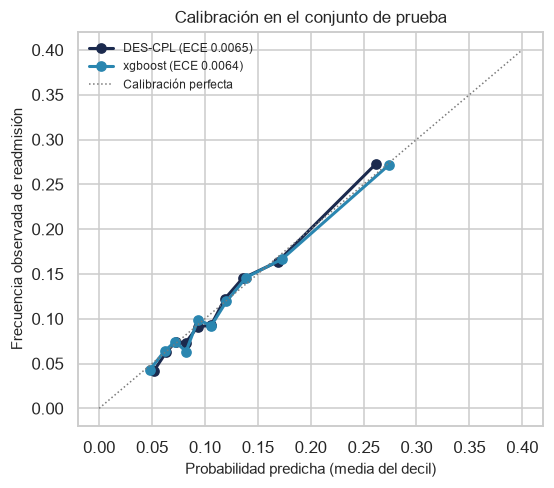

In [18]:
# Calibración: curva de fiabilidad por deciles de DES-CPL y del mejor benchmark.
if not pred_prueba.empty:
    fig, eje = plt.subplots(figsize=(5.2, 4.6))
    for nombre, color in [("DES-CPL", "#1B2A4E"), (REFERENCIA, "#2A86B0")]:
        tabla_cal = pd.DataFrame({"p": pred_prueba[nombre], "y": y_te})
        tabla_cal["bin"] = pd.qcut(tabla_cal["p"], 10, duplicates="drop")
        puntos = tabla_cal.groupby("bin", observed=True).agg(p=("p", "mean"), y=("y", "mean"))
        eje.plot(puntos["p"], puntos["y"], "o-", color=color, lw=2, ms=6,
                 label=f"{nombre} (ECE {error_calibracion(y_te, pred_prueba[nombre]):.4f})")
    tope = float(max(pred_prueba[["DES-CPL", REFERENCIA]].quantile(0.99).max(), 0.4))
    eje.plot([0, tope], [0, tope], ls=":", color=GRIS, lw=1, label="Calibración perfecta")
    eje.set_xlabel("Probabilidad predicha (media del decil)")
    eje.set_ylabel("Frecuencia observada de readmisión")
    eje.set_title("Calibración en el conjunto de prueba")
    eje.legend(fontsize=8)
    plt.tight_layout()
    plt.show()

In [19]:
# Predicción conforme inductiva por clase (α = 0,1). Calibración: predicciones
# fuera de pliegue de DES-CPL en el entrenamiento, que el modelo no usó para
# ajustar los modelos que las produjeron.
oof_des = leer(RUTA_PRUEBA_OOF)
if not oof_des.empty and not pred_prueba.empty:
    cobertura, resumen_conformal = evaluar_conformal(
        oof_des["y"], oof_des["DES-CPL"], y_te, pred_prueba["DES-CPL"], alfa=0.1)
    guardar_resultado(cobertura, "prueba_conformal")
    display(cobertura.round(4))
    print({k: round(v, 4) for k, v in resumen_conformal.items()})

,grupo,n,cobertura,cobertura nominal
0,Todos,19867,0.8900,0.9
1,No readmitidos,17604,0.8927,0.9
2,Readmitidos,2263,0.8688,0.9


{'cuantil_clase_0': 0.1799, 'cuantil_clase_1': 0.9273, 'tamano_medio': 1.6174, 'conjuntos_vacios': 0.0, 'conjuntos_con_ambas': 0.6174, 'conjuntos_solo_readmitido': 0.1265}


### 13.8.1. Lectura

**Desempeño.** En el conjunto de prueba (19 867 hospitalizaciones, 11.4 % readmitidas antes de 30 días), DES-CPL obtiene AUC-PR = 0.2293, AUC-ROC = 0.6661 y Brier = 0.0961. Queda quinto de doce, detrás de XGBoost (0.2315), el apilamiento logístico (0.2311), los pesos globales (0.2307) y CatBoost (0.2301). La diferencia con XGBoost es −0.0021 puntos de AUC-PR, con IC 95 % BCa por paciente [−0.0080, 0.0033]: el intervalo contiene el cero. Los cinco primeros caben en una franja de 0.0022, menor que la incertidumbre de muestreo. El conjunto de prueba repite así lo que mostró el bucle externo en 13.5: DES-CPL empata con los mejores, pero no los supera.

**Pruebas de hipótesis.** Las tres pruebas exigidas por la guía, corregidas por Holm, no rechazan H0 frente al mejor benchmark:
- Friedman encuentra diferencias globales entre modelos (χ² = 38.72, p = 1.3·10⁻⁵), pero Nemenyi no separa a DES-CPL de XGBoost (rangos 2.8 frente a 1.8; CD = 6.06).
- Nadeau-Bengio en los folds externos da t = −0.26 y p = 0.60.
- DeLong en prueba da z = −0.48 y p = 0.68.

DeLong sí muestra que DES-CPL supera con significancia a cinco de los siete modelos base (regresión logística, Bayes, k-NN, árbol, random forest y SVM; todos con p de Holm < 0.001). Frente a XGBoost, LightGBM y CatBoost no hay diferencia (p de Holm ≥ 0.58). **H1 no se confirma**, y se reporta como resultado negativo, tal como prevé `protocolo.md`.

**Estabilidad de DES-CPL.** El AUC-PR de DES-CPL en el conjunto de selección (0.2293) coincide con el de prueba (0.2293), así que la búsqueda de k, τ y λ no sobreajustó. La configuración elegida fue k = 20, τ = 0.0003 y λ = 0.9 con los cuatro modelos de mayor AUC-PR. Un λ tan cercano a 1 significa que la regla queda casi en una ponderación global y que la competencia local aporta poco. Es la misma tendencia de los folds externos (λ = 1, 1, 1, 0.5, 0.9) y es coherente con el límite informativo descrito en 13.6: las regiones del espacio de perfiles no contienen señal que distinga qué modelo acierta con qué paciente.

**Ablaciones en prueba (descriptivas, sin prueba formal).** Sobre un solo conjunto de prueba, estas diferencias son del orden de milésimas y no se interpretan como efectos:
- Quitar el encogimiento (0.2281) o medir la competencia por exactitud en lugar del Brier (0.2257) empeora el resultado.
- La poda, la selección dura (τ = 0) y la exclusión del paciente casi no cambian nada.
- La exclusión del paciente da un resultado idéntico por diseño: los pacientes de prueba no están en el conjunto de selección, así que solo actúa dentro del bucle de selección.

**Calibración.** El ECE de DES-CPL (0.0065, con bins por cuantiles) está entre los más bajos, junto con la regresión logística (0.0038), el apilamiento (0.0052) y XGBoost (0.0064). El único modelo mal calibrado es Naive Bayes (0.1218). Al combinar probabilidades ya calibradas, DES-CPL conserva esa calibración, como se ve en el diagrama de confiabilidad.

**Predicción conforme (Mondrian, α = 0.1).**
- **Cobertura.** Es de 0.890 en total y de 0.893 en los no readmitidos. En los readmitidos baja a 0.869, unos 5 errores estándar bajo la cobertura nominal de 0.9 con n = 2 263.
- **Causa probable de la falta de cobertura.** Se viola el supuesto de intercambiabilidad. Los puntajes de calibración salen de predicciones fuera de pliegue en el conjunto de selección, mientras que las de prueba salen de modelos base reentrenados sobre todo el entrenamiento, con una distribución de probabilidades algo distinta. Se declara como limitación.
- **Utilidad clínica de los conjuntos.** El tamaño medio del conjunto es 1.62. El 61.7 % de los pacientes recibe el conjunto {readmitido, no readmitido}, que no informa nada, y solo el 12.6 % recibe un conjunto con la clase readmitido sola. Con el AUC-ROC de 0.67 que permiten estas variables, el modelo solo puede descartar o señalar el riesgo con 90 % de garantía en una minoría de pacientes. Es otra forma de ver el límite explicativo de los datos.

**Conclusión de la sección.** DES-CPL es competitivo con el estado del arte (XGBoost, CatBoost y LightGBM) y con los ensambles estáticos, está bien calibrado y supera con significancia a los modelos base más simples. No mejora al mejor modelo individual. La evidencia de los folds externos y del conjunto de prueba coincide: con estas variables, el techo de AUC-PR ronda 0.23 para cualquier método evaluado.
